# Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

In [1]:
# Part a) is analytical and belongs in the theory section of your report.
# You may want to define the cost functions, their gradients and the
# activation functions (with derivatives) here as Python functions.

### imports
# basics
import numpy as np
import matplotlib.pyplot as plt
import warnings
import xarray as xr
# scikit-learn
from sklearn.model_selection import train_test_split, KFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report

# jax (automatic differentiation, used to check our own gradients)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, as in numpy

### our own functions, sorted by topic (the .py files in the same folder as this notebook)
# activation functions and their derivatives
from activations import (ReLU, ReLU_der, leaky_ReLU, leaky_ReLU_der, sigmoid, sigmoid_der,
                         identity, identity_der, softmax)
# cost functions, derivatives and error metrics
from costs import (mse, mse_der, MSE, R2, mse_der_batch, output_error_softmax_ce, cross_entropy, accuracy)
# the Runge function and the data preparation
from data_prep import runge, prepare_data
# the feed-forward network: layers, feed forward, backpropagation, set-up
from feedforward import (create_layers, feed_forward, cost, feed_forward_saver, backpropagation,
                         create_layers_batch, feed_forward_batch, feed_forward_saver_batch, cost_batch,
                         backpropagation_batch, init_layers, predict, setup_NN)
# gradient-descent update rules
from optimisers import gd_step, momentum_step, optimiser_step
# training loop and CV of the regression network (part b/c)
from training import train, cv_mse_nopen
# OLS / Ridge / Lasso benchmarks from project 1
from ols_regression import cost_ols, closed_form, gradient, OLS_regression, fit_poly, poly_cv
# plot helpers
from plotting import heatmap_nopen
# part d): L1 / L2 penalties
from task_d import (penalty_grad, backprop_penalised, train_penalised, build_net, penalised_cost_jax,
                    check_gradient_jax, cv_mse, lam_label)

from reading_noresm import read_noresm_cmor, Modelinfo, global_avg
import functions_heatbudget as fhb

### random seed for reproducibility
rng = np.random.default_rng(2026)

### defining colors and fontsize for plotting
BLUE, RED, GREEN, GREY = "#004488", "#BB5566", "#228833", "#777777"
train_color = "#32A911"
test_color = "#048582"

label_fontsize = 14
title_fontsize=16
tick_fontsize=13
legend_fontsize=11


### Reading the data

In [ ]:

def read_data(period="historical",area="global"):
    """    INPUT    """
    modelname = "NorESM2-MM"  # name of model
    realiz = "r1i1p1f1"  # ensemble member
    """ END OF INPUT """

    if period == "historical":
        #Information of experiments in each period
        exps = "historical"
        activity_id = "CMIP"

    elif period == "ssp585":
        #Information of experiments in each period
        exps = "ssp585"
        activity_id = "ScenarioMIP"
    elif period == "sample":
        #Information of experiments in each period
        exps = "historical"
        activity_id = "CMIP"
    else:
        raise ValueError("Period must be either 'historical', 'ssp585', or 'sample'.")

    model = Modelinfo(name=modelname, activity_id=activity_id, expid=exps, realiz=realiz)

    #Reading the different experiments and getting the 30 year periods
    if period == "historical":
        var = fhb.read_atmos_data(model=model,first_year = 1985,last_year = 2014)
        base = fhb.read_atmos_data(model=model,first_year = 1850,last_year = 1879)
    elif period == "ssp585":
        var = fhb.read_atmos_data(model=model,first_year = 2071,last_year = 2100)
        base = fhb.read_atmos_data(model=model,first_year = 2015,last_year = 2029)
    elif period == "sample":
        var = xr.open_dataset("ds_sample.nc")
        base = xr.open_dataset("base_sample.nc")

    if not period == "sample": # the sample run is already averaged over the global region, so we don't need to compute the mean again
        if area == "global":
            var_mean = global_avg(var.drop_vars(["time_bnds","lat_bnds","lon_bnds"]))  # Global average of the dataset
            base_mean = global_avg(base.drop_vars(["time_bnds","lat_bnds","lon_bnds"]))  # Global average of the dataset        
        elif area == "arctic":
            var_mean = global_avg(var.drop_vars(["time_bnds","lat_bnds","lon_bnds"]).sel(lat=slice(60,90)))  # Arctic average of the dataset
            base_mean = global_avg(base.drop_vars(["time_bnds","lat_bnds","lon_bnds"]).sel(lat=slice(60,90)))  # Arctic average of the dataset

    return var_mean, base_mean


### Calculating the SEB contributions analytically

/nird/datapeak/NS9560K/users/andrear/FYS-STK4155/reading_noresm.py:222: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  with xr.open_mfdataset(
/nird/datapeak/NS9560K/users/andrear/FYS-STK4155/reading_noresm.py:222: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  with xr.open_mfdataset(
/nird/datapeak/NS9560K/users/andrear/FYS-STK4155/reading_noresm.py:222: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 

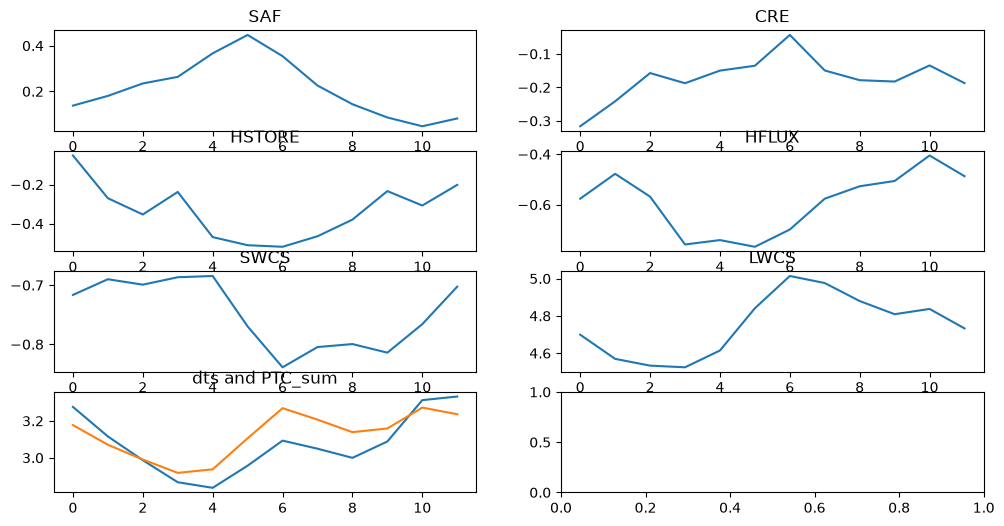

In [3]:
ds, base = read_data(period="historical")
    
ds = ds.sel(time=slice('1985-01-01', '2014-12-31'))  # Select the time range for training and testing

ds_mean = global_avg(ds.drop_vars(["time_bnds","lat_bnds","lon_bnds"]))  # Global average of the dataset
base_mean = global_avg(base.drop_vars(["time_bnds","lat_bnds","lon_bnds"])).mean(dim="time")  # Global average of the dataset

ds_fut, base_fut = read_data(period="ssp585")

dsfut_mean = global_avg(ds_fut.drop_vars(["time_bnds","lat_bnds","lon_bnds"]))  # Global average of the dataset

dsfut_mean = dsfut_mean.groupby('time.month').mean() 
ds_mean = ds_mean.groupby('time.month').mean() 
month = np.arange(1,13)

    
ptc_temp = fhb.partial_temperature_contributions(dsfut_mean,ds_mean)

fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_temp.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_temp.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_temp.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_temp.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_temp.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_temp.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_temp.dts[:12].values, label="dts")
ax[3,0].plot(ptc_temp.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

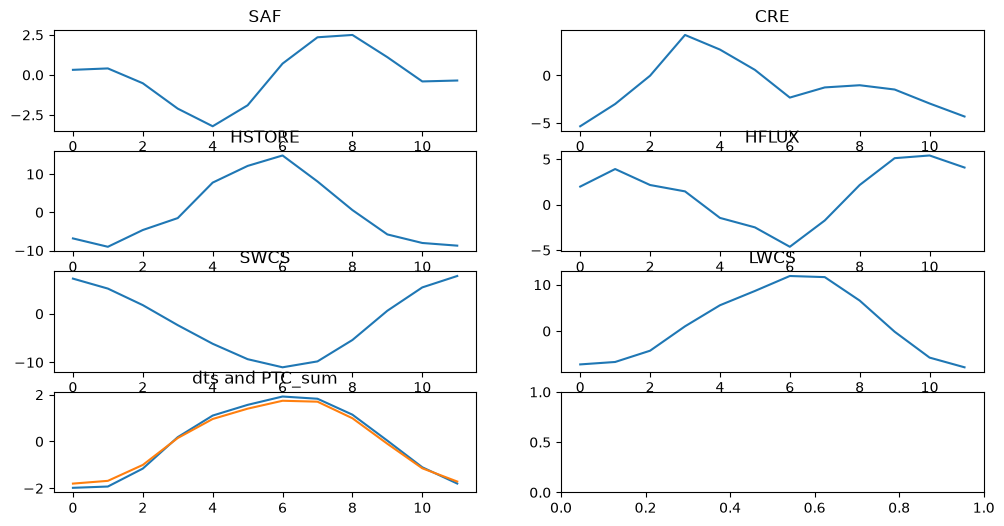

In [28]:
ds, base = read_data(period="historical")

ds_mean = ds
base_mean = base.mean(dim="time")  # Global average of the dataset        

ptc_temp = fhb.partial_temperature_fluxes(ds_mean,base_mean)

fig, ax = plt.subplots(4,2, figsize=(12, 6))

# ptc_temp = fhb.abs_temperature_decomposition(ds_mean)
ax[0,0].plot(ptc_temp.SAF[:12].values, label="SAF")
ax[0,0].set_title("SAF")

ax[0,1].plot(ptc_temp.CRE[:12].values, label="CRE")
ax[0,1].set_title("CRE")
ax[1,0].plot(ptc_temp.HSTORE[:12].values, label="HSTORE")
ax[1,0].set_title("HSTORE")
ax[1,1].plot(ptc_temp.HFLUX[:12].values, label="HFLUX")
ax[1,1].set_title("HFLUX")  
ax[2,0].plot(ptc_temp.SWCS[:12].values, label="SWCS")
ax[2,0].set_title("SWCS")
ax[2,1].plot(ptc_temp.LWCS[:12].values, label="LWCS")
ax[2,1].set_title("LWCS")
ax[3,0].plot(ptc_temp.dts[:12].values, label="dts")
ax[3,0].plot(ptc_temp.PTC_sum[:12].values, label="PTC_sum")
ax[3,0].set_title("dts and PTC_sum")

plt.show()

In [29]:
# Load SEB data
def load_SEB_data():
    """Returns numpy arrays (x_tr, y_tr, x_te, y_te) with shapes (N, 6) and (N, 1).
    Works directly with the own NN code (numpy/JAX); use torch.tensor(...) for the PyTorch model."""
    
    ds, base = read_data(period="historical")
    
    ds_mean = ds 
    base_mean = base.mean(dim="time") 
    ptc_temp = fhb.partial_temperature_fluxes(ds_mean,base_mean)


    SAF = ptc_temp.SAF #surface albedo feedback
    CRE = ptc_temp.CRE #cloud radiative effect
    HSTORE = ptc_temp.HSTORE #heat storage
    HFLUX = ptc_temp.HFLUX  #heat fluxes
    SWCS = ptc_temp.SWCS #shortwave clear-sky
    LWCS = ptc_temp.LWCS #longwave clear-sky
    dts = ptc_temp.dts #change in surface temperature (dts = ts - ts_base)
    
    # Stack inputs and normalize
    input_tr = np.stack([SAF.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       CRE.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       HSTORE.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       HFLUX.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       SWCS.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       LWCS.sel(time=slice('1985-01-01', '2004-12-31')).values], axis=1)

    input_te = np.stack([SAF.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       CRE.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       HSTORE.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       HFLUX.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       SWCS.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       LWCS.sel(time=slice('2005-01-01', '2014-12-31')).values], axis=1)

    # Targets as numpy arrays of shape (N, 1)
    target_tr = dts.sel(time=slice('1985-01-01', '2004-12-31')).values.reshape(-1, 1)
    target_te = dts.sel(time=slice('2005-01-01', '2014-12-31')).values.reshape(-1, 1)

    # Standardise both sets with the statistics of the TRAINING set
    x_mean, x_std = input_tr.mean(axis=0), input_tr.std(axis=0)
    y_mean, y_std = target_tr.mean(), target_tr.std()

    input_tr = (input_tr - x_mean) / x_std
    input_te = (input_te - x_mean) / x_std
    target_tr = (target_tr - y_mean) / y_std
    target_te = (target_te - y_mean) / y_std

    return input_tr, target_tr, input_te, target_te

### CV to find best hyperparameters

Inputs shape: (240, 6)
Targets shape: (240, 1)
[(True, True), (True, True)]
Done l2 grid search: (7, 5) (gamma x lambda)
Done l1 grid search: (7, 5) (gamma x lambda)


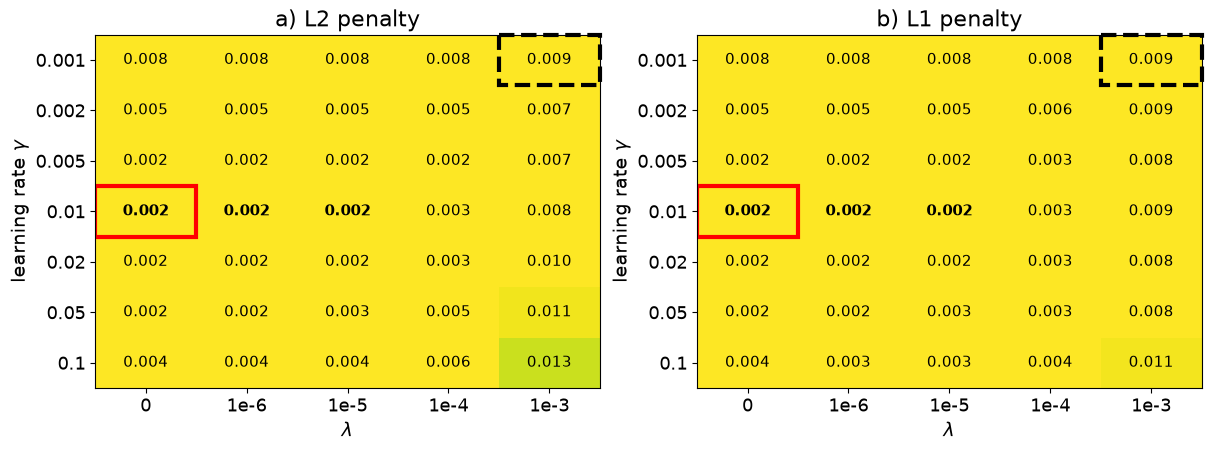

learning rate used from here on: gamma = 0.01
penalty used from here on: lambda = 1e-05


In [6]:
def cv_mse(x_tr, y_tr, hidden, gamma, lam, norm, k=5, epochs=200):
    """5-fold CV MSE on the training data for one network setting (mean and standard error over the folds).
    The validation MSE of a fold is averaged over the last 10 epochs, to remove jittering."""
    scores = []
    for tr, va in KFold(k, shuffle=True, random_state=2026).split(x_tr):
        layers, act, der = setup_NN(x_tr.shape, y_tr.shape, hidden, activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)

        _, hist = train_penalised(layers, x_tr[tr], y_tr[tr], x_tr[va], y_tr[va],
                                  "adam", act, der, gamma, epochs, lam, norm)
        scores.append(hist[-10:, 2].mean())
    return float(np.mean(scores)), float(np.std(scores)) / np.sqrt(len(scores))   # mean and standard error, as cv_mse_nopen


# Load and preprocess data
x_tr, y_tr, x_te, y_te = load_SEB_data()

# Define network parameters
input_size = x_tr.shape[1]  # variables used for the equation
hidden_size = 50
output_size = y_tr.shape[1]  # Ts

# Print shapes 
print(f"Inputs shape: {x_tr.shape}")
print(f"Targets shape: {y_tr.shape}")


# Initialize model
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)

#Testing with JAX:
g_hand = backpropagation_batch(x_tr, layers0, activation_funcs, y_tr, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers0, x_tr, activation_funcs, y_tr)

# checking that the functions above agree with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax) ])




lam_grid = [0.0, 1e-6, 1e-5, 1e-4, 1e-3] # lambda = 0 is the unregularised network
gamma_grid = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1] # learning rates for Adam
lam_labels = [lam_label(l) for l in lam_grid]
norms = ["l2", "l1"]

grid_gl, grid_gl_se = {}, {} # norm -> (len(gamma_grid) x len(lam_grid)) arrays: CV MSE and its standard error
for norm in norms:
    res = np.array([[cv_mse(x_tr, y_tr, [50], g, lam, norm) for lam in lam_grid] for g in gamma_grid]) # last axis: (mean, se)
    grid_gl[norm], grid_gl_se[norm] = res[..., 0], res[..., 1]
    print(f"Done {norm} grid search: {grid_gl[norm].shape} (gamma x lambda)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, norm, name in zip(axes, norms, ["a) L2 penalty", "b) L1 penalty"]):
    heatmap_nopen(ax, grid_gl[norm], gamma_grid, lam_labels, name, r"learning rate $\gamma$", r"$\lambda$", grid_se=grid_gl_se[norm],
                   label_fontsize=label_fontsize, title_fontsize=title_fontsize, tick_fontsize=tick_fontsize, annot_fontsize=legend_fontsize)
# black dashed frame to choose best according to 1 se rule 
    ax.add_patch(plt.Rectangle((lam_grid.index(1e-3) - 0.5, gamma_grid.index(0.001) - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--", clip_on=False))
# fig.suptitle("5-fold CV MSE, Adam, 1 hidden layer with 50 ReLU nodes (red = lowest, black = 1-se rule, bold = within 1 se)")
# plt.savefig("./figures/partd_lambda_gamma.png", dpi=500)
plt.show()

# One learning rate for the rest of part d): the best one over both grids (all lambda)
best_gamma = min(((grid_gl[n][i, j], gamma_grid[i]) for n in norms
                  for i in range(len(gamma_grid)) for j in range(len(lam_grid))))[1]
best_penalty = 1e-5  # the one chosen by the black dashed frame in the heatmaps above

print("learning rate used from here on: gamma =", best_gamma)
print("penalty used from here on: lambda =", best_penalty)

In [30]:
best_gamma = 0.01
best_penalty = 1e-5

### Pytorch NN

Inputs shape: torch.Size([240, 6])
Targets shape: torch.Size([240, 1])

Sample Inputs:
 tensor([[ 0.2141, -1.6750, -0.7866,  0.2480,  1.3624, -1.4170],
        [ 0.2681, -0.7065, -1.0464,  0.8429,  1.0556, -1.3459],
        [-0.2995,  0.5250, -0.5257,  0.3011,  0.5472, -1.0166],
        [-1.2701,  2.2987, -0.1550,  0.0851, -0.0680, -0.3043],
        [-1.9445,  1.6624,  0.9467, -0.8142, -0.6402,  0.3110]])

Sample Targets:
 tensor([[-1.4828],
        [-1.4452],
        [-0.9254],
        [-0.0145],
        [ 0.6108]])
Epoch [100/500], Loss: 0.0138
Epoch [200/500], Loss: 0.0073
Epoch [300/500], Loss: 0.0059
Epoch [400/500], Loss: 0.0048
Epoch [500/500], Loss: 0.0039
Training complete.

Test MSE = 0.0060, R^2 = 0.994


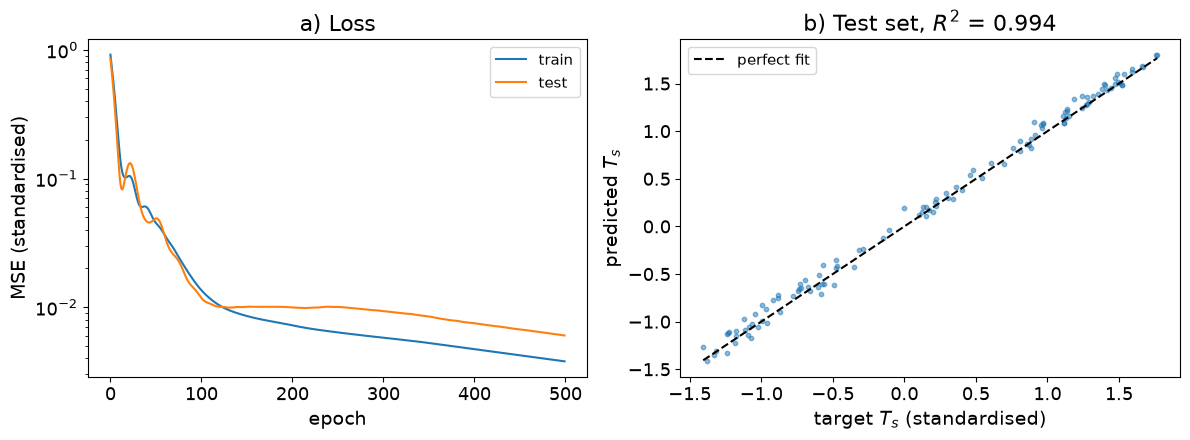

In [13]:
import torch
import torch.nn as nn
import torch.optim as optim

#The skeleton in this cell is provided by Claude, I have made some changes to fit the data and problem.

# Define the Neural Network
class SurfaceEnergyNet(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SurfaceEnergyNet, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)
    
    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x



# Main Training Loop: returns the model and the loss history
def train_network(model, inputs, targets, test_inputs=None, test_targets=None,
                  epochs=500, learning_rate=0.01, lam=0.0, norm="l2"):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)
    train_losses, test_losses = [], []
    for epoch in range(epochs):
        # Forward pass
        model.train()
        outputs = model(inputs)
        mse_loss = criterion(outputs, targets)

        # Apply L1 or L2 regularization if specified
        if lam > 0:
            weights = [model.fc1.weight, model.fc2.weight]   # only penalising the weights, biases excluded
            l1_norm = sum(w.abs().sum() for w in weights)
            l2_norm = sum(w.pow(2).sum() for w in weights)
            # l1_norm = sum(p.abs().sum() for p in model.parameters())
            # l2_norm = sum(p.pow(2).sum() for p in model.parameters())
            if norm == "l1":
                loss = mse_loss + lam * l1_norm
            elif norm == "l2":
                loss = mse_loss + lam * l2_norm
        else:
            loss = mse_loss

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        train_losses.append(mse_loss.item())
        if test_inputs is not None:
            model.eval()
            with torch.no_grad():
                test_losses.append(criterion(model(test_inputs), test_targets).item())
        
        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}')
    
    print("Training complete.")
    return model, train_losses, test_losses


# Example usage
if __name__ == "__main__":
    # Define network parameters
    input_size = 6  # number of input features
    hidden_size = 10
    output_size = 1  # Ts
    gamma = best_gamma  # Use the best gamma found from the grid search
    penalty = best_penalty # Use the best penalty found from the grid search

    # Initialize model
    model = SurfaceEnergyNet(input_size, hidden_size, output_size)
    
    # Load and preprocess data (numpy), then convert to torch tensors for the PyTorch model only
    x_tr_np, y_tr_np, x_te_np, y_te_np = load_SEB_data()
    x_tr, y_tr, x_te, y_te = [torch.tensor(a, dtype=torch.float32)
                              for a in (x_tr_np, y_tr_np, x_te_np, y_te_np)]
    

    # Print shapes to verify
    print(f"Inputs shape: {x_tr.shape}")
    print(f"Targets shape: {y_tr.shape}")

    # Print a small sample
    print("\nSample Inputs:\n", x_tr[:5])
    print("\nSample Targets:\n", y_tr[:5])

    # Train the model
    trained_model, train_losses, test_losses = train_network(
        model, x_tr, y_tr, x_te, y_te, learning_rate=gamma, lam=penalty, norm="l2", epochs=500)

    # Predictions on the test set (no gradients needed)
    trained_model.eval()
    with torch.no_grad():
        pred = trained_model(x_te).numpy().ravel()
    true = y_te.numpy().ravel()
    r2 = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)
    print(f"\nTest MSE = {np.mean((true - pred) ** 2):.4f}, R^2 = {r2:.3f}")

    # Plot: a) loss curves, b) predicted vs. target on the test set
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

    ax1.semilogy(train_losses, label="train")
    ax1.semilogy(test_losses, label="test")
    ax1.set_xlabel("epoch", fontsize=label_fontsize)
    ax1.set_ylabel("MSE (standardised)", fontsize=label_fontsize)
    ax1.set_title("a) Loss", fontsize=title_fontsize)
    ax1.tick_params(axis="both", which="both", labelsize=tick_fontsize)
    ax1.legend(fontsize=legend_fontsize)

    ax2.scatter(true, pred, s=10, alpha=0.5)
    lims = [true.min(), true.max()]
    ax2.plot(lims, lims, "k--", label="perfect fit")
    ax2.set_xlabel("target $T_s$ (standardised)", fontsize=label_fontsize)
    ax2.set_ylabel("predicted $T_s$", fontsize=label_fontsize)
    ax2.set_title(f"b) Test set, $R^2$ = {r2:.3f}", fontsize=title_fontsize)
    ax2.tick_params(axis="both", which="both", labelsize=tick_fontsize)
    ax2.legend(fontsize=legend_fontsize)

    plt.tight_layout()
    plt.show()


### Using the FFNN from Project 2

In [14]:
#TEST on the functions from project 2 (this is the same code as in project 2, to make sure no bug has appeared for project 3):
inputs = np.random.rand(1000, 4)

layers_b = create_layers_batch(4, [6, 5, 3])
layers_single = [(W.T, b) for W, b in layers_b]
out_batch = feed_forward_batch(inputs, layers_b, [ReLU, ReLU, sigmoid])
out_single = feed_forward(inputs[0], layers_single, [ReLU, ReLU, sigmoid])
print(out_batch.shape)
print("max difference on sample 0:", np.max(np.abs(out_batch[0] - out_single)))

#Testing the code with jax, both for single input and batch input
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

xx = np.random.rand(network_input_size)
target = np.random.rand(4)

layer_grads = backpropagation(xx, layers, activation_funcs, target, activation_ders)

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, xx, [sigmoid, ReLU], target)

# checking that the functions above agree with jax to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

inputs = np.random.rand(10, 2)
targets = np.random.rand(10, 4)
layers_b = create_layers_batch(2, [3, 4])

g_hand = backpropagation_batch(inputs, layers_b, activation_funcs, targets, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers_b, inputs, activation_funcs, targets)

for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax):
    print("dW", dW.shape, np.allclose(dW, dW_j), "   db", db.shape, np.allclose(db, db_j))

(1000, 3)
max difference on sample 0: 0.0
[(True, True), (True, True)]
dW (2, 3) True    db (3,) True
dW (3, 4) True    db (4,) True


Inputs shape: (240, 6)
Targets shape: (240, 1)
[(True, True), (True, True)]
noise level based on the test data: 1.0980  (sigma^2 = 0.010000000000000002)

Test MSE = 0.0013, R^2 = 0.999
OLS test MSE = 0.0013, R^2 = 0.999


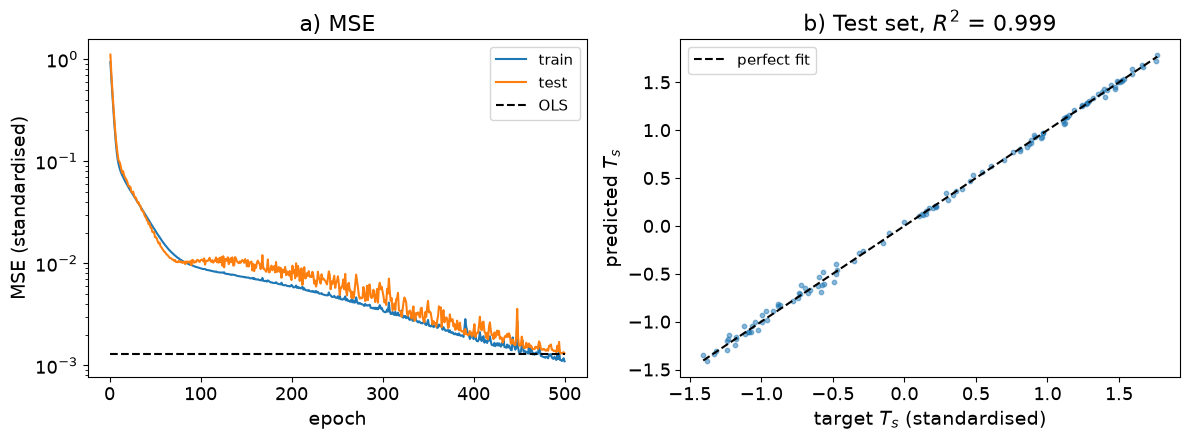

In [15]:
# Preparing data for training and testing
# Load and preprocess data
x_tr, y_tr, x_te, y_te = load_SEB_data()

# Define network parameters
input_size = x_tr.shape[1]  # variables used for the equation
hidden_size = 50
output_size = y_tr.shape[1]  # Ts

# Print shapes 
print(f"Inputs shape: {x_tr.shape}")
print(f"Targets shape: {y_tr.shape}")


# Initialize model
#model = SurfaceEnergyNet(input_size, hidden_size, output_size)
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)


#Testing with JAX:
g_hand = backpropagation_batch(x_tr, layers0, activation_funcs, y_tr, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers0, x_tr, activation_funcs, y_tr)

# checking that the functions above agree with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax) ])

# Getting the noise floor on the test points
sigma = 0.1
noise_floor = np.mean((y_te - runge(x_te)) ** 2)
print(f"noise level based on the test data: {noise_floor:.4f}  (sigma^2 = {sigma**2})")

layers, hist  = train_penalised(layers0, x_tr, y_tr, x_te, y_te, step="adam", act=activation_funcs, act_der=activation_ders, gamma=0.001, epochs=500,lam=best_penalty, norm="l2") #currently using full-batch, not SGD

prediction = feed_forward_batch(x_te, layers, activation_funcs)

pred_sort = np.asarray(prediction).ravel() 
true = y_te.ravel()
r2 = 1 - np.sum((true - pred_sort) ** 2) / np.sum((true - true.mean()) ** 2)
print(f"\nTest MSE = {np.mean((true - pred_sort) ** 2):.4f}, R^2 = {r2:.3f}")


#Getting the OLS for comparison:

# Design matrix with intercept column
A_tr = np.hstack([x_tr, np.ones((x_tr.shape[0], 1))])
A_te = np.hstack([x_te, np.ones((x_te.shape[0], 1))])

theta_ols = closed_form(A_tr, y_tr)              # lam=0 -> plain OLS (fit on training set only)
pred_ols = A_te @ theta_ols                      # standardised prediction on the test set

mse_ols = np.mean((y_te - pred_ols) ** 2)
r2_ols = 1 - np.sum((y_te - pred_ols) ** 2) / np.sum((y_te - y_te.mean()) ** 2)
print(f"OLS test MSE = {mse_ols:.4f}, R^2 = {r2_ols:.3f}")

 

# Plot: a) loss curves, b) predicted vs. target on the test set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.semilogy(hist[:,0],hist[:,1], label="train")
ax1.semilogy(hist[:,0],hist[:,2], label="test")
ax1.hlines(mse_ols, hist[0,0], hist[-1,0], colors="k", linestyles="--", label="OLS")
ax1.set_xlabel("epoch", fontsize=label_fontsize)
ax1.set_ylabel("MSE (standardised)", fontsize=label_fontsize)
ax1.set_title("a) MSE", fontsize=title_fontsize)
ax1.tick_params(axis="both", which="both", labelsize=tick_fontsize)
ax1.legend(fontsize=legend_fontsize)

ax2.scatter(true, pred_sort, s=10, alpha=0.5)
lims = [true.min(), true.max()]
ax2.plot(lims, lims, "k--", label="perfect fit")
ax2.set_xlabel("target $T_s$ (standardised)", fontsize=label_fontsize)
ax2.set_ylabel("predicted $T_s$", fontsize=label_fontsize)
ax2.set_title(f"b) Test set, $R^2$ = {r2:.3f}", fontsize=title_fontsize)
ax2.tick_params(axis="both", which="both", labelsize=tick_fontsize)
ax2.legend(fontsize=legend_fontsize)

plt.tight_layout()
plt.show()






### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, KFold

x_tr, y_tr, x_te, y_te = load_SEB_data()

# 1) Basic fit. ravel() because sklearn wants a 1D target (N,), not (N, 1)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=1/3,
                           oob_score=True, random_state=2026, n_jobs=-1)
rf.fit(x_tr, y_tr.ravel())

pred_rf = rf.predict(x_te)                           # standardised prediction, shape (N,)
t = y_te.ravel()
mse_rf = np.mean((t - pred_rf) ** 2)
r2_rf = 1 - np.sum((t - pred_rf) ** 2) / np.sum((t - t.mean()) ** 2)
print(f"RF test MSE = {mse_rf:.4f}, R^2 = {r2_rf:.3f}, OOB R^2 = {rf.oob_score_:.3f}")

# 2) Hyperparameters chosen by CV on the training set only (same folds as for the NN)
param_grid = {"max_features": [0.33, 0.5, 1.0],
              "min_samples_leaf": [1, 3, 5, 10],
              "max_depth": [None, 5, 10]}
gs = GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=2026, n_jobs=-1),
                  param_grid, cv=KFold(5, shuffle=True, random_state=2026),
                  scoring="neg_mean_squared_error")
gs.fit(x_tr, y_tr.ravel())
print("best:", gs.best_params_, " CV MSE:", -gs.best_score_)
rf_best = gs.best_estimator_
pred_rf = rf_best.predict(x_te)

# 3) Feature importance (which SEB term the forest uses)
names = ["SAF", "CRE", "HSTORE", "HFLUX", "SWCS", "LWCS"]
for n, imp in sorted(zip(names, rf_best.feature_importances_), key=lambda p: -p[1]):
    print(f"{n:7s} {imp:.3f}")



RF test MSE = 0.0213, R^2 = 0.978, OOB R^2 = 0.985
best: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1}  CV MSE: 0.010453403483291289
LWCS    0.965
SWCS    0.026
HFLUX   0.003
SAF     0.003
CRE     0.001
HSTORE  0.001


NameError: name 'y_std' is not defined

#### Temperature results

In [ ]:
#Compare the temperature results

ds, base = read_data()
ts = global_avg(ds['ts']) - global_avg(base['ts']).mean(dim="time")   # Surface temperature

target_tr = ts.sel(time=slice('1985-01-01', '2004-12-31')).values.reshape(-1, 1)
# Standardise both sets with the statistics of the TRAINING set
y_mean, y_std = target_tr.mean(), target_tr.std()

# Retrieving the absolute values 
pred_abs = pred * y_std + y_mean
y_te_abs = y_te * y_std + y_mean
prediction_abs = prediction * y_std + y_mean

pred_rf_abs = pred_rf * y_std + y_mean

pred_ols_abs = pred_ols * y_std + y_mean

plt.plot(pred_abs, label ="pytorch NN prediction")
plt.plot(prediction_abs, label ="Own NN prediction")
# plt.plot(pred_rf_abs, label="Random forest")
plt.plot(y_te_abs, label ="True values")
plt.plot(np.arange(len(ptc_temp.PTC_sum.sel(time=slice("2005-01-01", "2014-12-31")))), ptc_temp.PTC_sum.sel(time=slice("2005-01-01", "2014-12-31")), label ="PTC sum")
plt.xticks(np.arange(0, len(y_te), 12), np.arange(2005, 2015))
plt.legend()
plt.xlabel("Year")
plt.ylabel("Surface temperature (K)")
plt.title("Comparison of predictions with true values")
plt.show()

KeyboardInterrupt: 

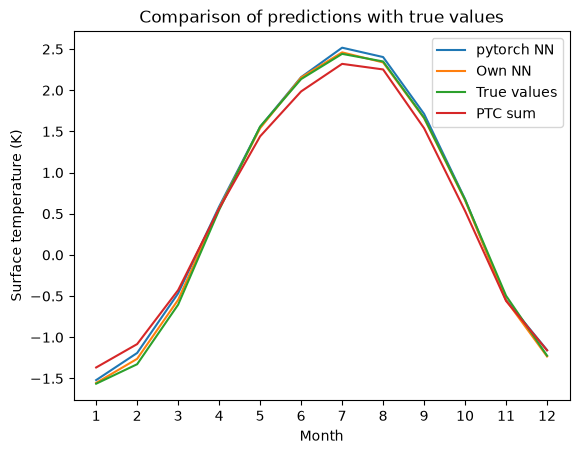

In [ ]:
time = ptc_temp.PTC_sum.sel(time=slice("2005-01-01", "2014-12-31")).time

# np.asarray(...).ravel() turns torch/JAX/numpy arrays of shape (N, 1) into plain 1D numpy arrays
ds_cmp = xr.Dataset(
    data_vars={
        "pytorch NN": ("time", np.asarray(pred_abs).ravel()),
        "Own NN": ("time", np.asarray(prediction_abs).ravel()),
        "True values": ("time", np.asarray(y_te_abs).ravel()),
        "PTC sum": ("time", np.asarray(ptc_temp.PTC_sum.sel(time=time)).ravel()),
    },
    coords={"time": time},
)
# ds_cmp: add  "Random forest": ("time", np.asarray(pred_rf_abs).ravel()),

# Monthly climatology (mean over the years 2005-2014)
ds_month = ds_cmp.groupby("time.month").mean()

for name in ds_month.data_vars:
    plt.plot(ds_month.month, ds_month[name], label=name)
plt.xticks(np.arange(1, 13))
plt.legend()
plt.xlabel("Month")
plt.ylabel("Surface temperature (K)")
plt.title("Comparison of predictions with true values")
plt.show()


### SHAP

test MSE, mean predictor: 1.0304,  OLS: 0.0013
epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff
    1        1.44   1.766      
    2        1.40   1.710      
    5        1.28   1.550      
   10        1.10   1.320      
   20        0.84   0.972      
   50        0.41   0.450      
  100        0.14   0.164      
  200        0.07   0.079      
  500        0.03   0.030      
 1000        0.01   0.010      
GD 50x1, 1000 epochs      train cost 1.490   test cost 1.824


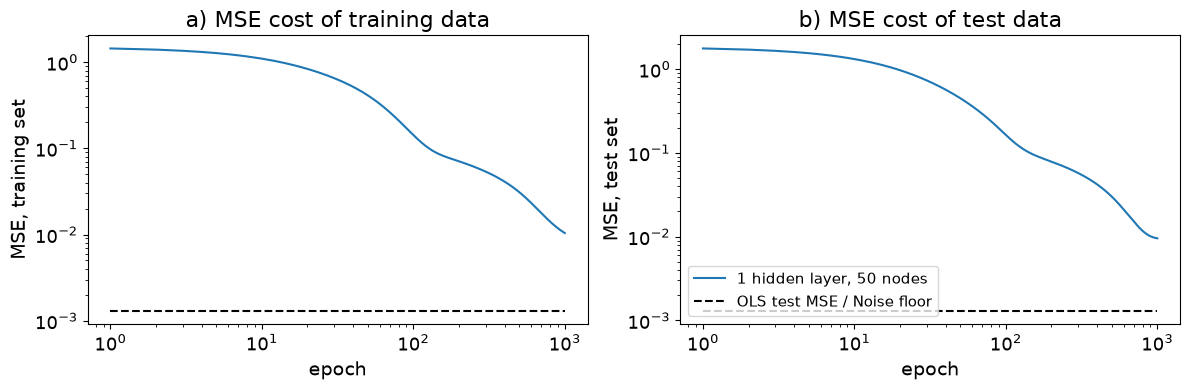

In [40]:
# Reference levels for the test MSE (y is standardised, so the mean predictor is about 1)
mean_mse = np.mean((y_te - y_tr.mean()) ** 2)          # always predict the training mean

# OLS on the 10 inputs (+ intercept), fitted on the training set only
A_tr = np.hstack([x_tr, np.ones((x_tr.shape[0], 1))])
A_te = np.hstack([x_te, np.ones((x_te.shape[0], 1))])
beta, *_ = np.linalg.lstsq(A_tr, y_tr, rcond=None)
ols_test_mse = np.mean((y_te - A_te @ beta) ** 2)

noise_floor = ols_test_mse    # keeps the later plotting cells working
print(f"test MSE, mean predictor: {mean_mse:.4f},  OLS: {ols_test_mse:.4f}")


print("epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff")
for e in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]:
    g = hist[e - 1]
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2]))

for name, L in [("GD 50x1, 1000 epochs", layers0)]:
    print("%-25s train cost %.3f   test cost %.3f"
          % (name,  float(cost_batch(L, x_tr, activation_funcs, y_tr)),
             float(cost_batch(L, x_te, activation_funcs, y_te))))

#Plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(hist[:, 0], hist[:, 1], label="1 hidden layer, 50 nodes")
# ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist[0, 0], xmax=hist[-1, 0], colors='k', linestyles='dashed', label="OLS test MSE / Noise floor")

ax1.set_xlabel("epoch", fontsize=label_fontsize); ax1.set_ylabel("MSE, training set", fontsize=label_fontsize); ax1.set_xscale("log")#; ax1.set_yscale("log")
ax1.set_title("a) MSE cost of training data", fontsize=title_fontsize)
ax1.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.semilogy(hist[:, 0], hist[:, 2], label="1 hidden layer, 50 nodes")
# ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist[0, 0], xmax=hist[-1, 0], colors='k', linestyles='dashed', label="OLS test MSE / Noise floor")
ax2.set_xlabel("epoch", fontsize=label_fontsize); ax2.set_ylabel("MSE, test set", fontsize=label_fontsize); ax2.set_xscale("log")
ax2.set_title("b) MSE cost of test data",fontsize=title_fontsize)
ax2.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.legend(fontsize=legend_fontsize,loc="best")

# fig.suptitle("Comparison of hidden layers and nodes")
plt.tight_layout()
# plt.savefig("./figures/NN_50x1_100x2.png", dpi=500)
plt.show()

# print("MSE train OLS:", MSE(OLS_regression(x_tr, y_tr),y_tr))
# print("MSE test OLS:", MSE(OLS_regression(x_te, y_te),y_te))

In [ ]:
# Load CMIP6 data
def load_cmip6_data():
    """Returns numpy arrays (x_tr, y_tr, x_te, y_te) with shapes (N, 10) and (N, 1).
    Works directly with the own NN code (numpy/JAX); use torch.tensor(...) for the PyTorch model."""
    ds, base = read_data()
    # Extract variables and preprocess them
    rsds = global_avg(ds['rsds']) - global_avg(base['rsds']).mean(dim="time")  # Downwelling shortwave radiation
    rlds = global_avg(ds['rlds']) - global_avg(base['rlds']).mean(dim="time")  # Downwelling longwave radiation
    rlns = global_avg(ds['rlns']) - global_avg(base['rlns']).mean(dim="time")  # Net longwave radiation
    hfss = global_avg(ds['hfss']) - global_avg(base['hfss']).mean(dim="time")   # Sensible heat flux
    hfls = global_avg(ds['hfls']) - global_avg(base['hfls']).mean(dim="time")   # Latent heat flux
    rsuscs = global_avg(ds['rsuscs']) - global_avg(base['rsuscs']).mean(dim="time")  # Upwelling shortwave radiation clear-sky
    rsdscs = global_avg(ds['rsdscs']) - global_avg(base['rsdscs']).mean(dim="time")  # Downwelling shortwave radiation clear-sky
    rlnscs = global_avg(ds['rlnscs']) - global_avg(base['rlnscs']).mean(dim="time")  # Net longwave radiation clear-sky
    rldscs = global_avg(ds['rldscs']) - global_avg(base['rldscs']).mean(dim="time")  # Net longwave radiation clear-sky
    rlus = global_avg(ds['rlus']) - global_avg(base['rlus']).mean(dim="time")  # Upwelling longwave radiation

    ts = global_avg(ds['ts']) - global_avg(base['ts']).mean(dim="time")   # Surface temperature

    # Stack inputs and normalize
    input_tr = np.stack([rsds.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlds.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlns.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       hfss.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       hfls.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rsuscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rsdscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlnscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rldscs.sel(time=slice('1985-01-01', '2004-12-31')).values,
                       rlus.sel(time=slice('1985-01-01', '2004-12-31')).values], axis=1)

    input_te = np.stack([rsds.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlds.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlns.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       hfss.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       hfls.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rsuscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rsdscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlnscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rldscs.sel(time=slice('2005-01-01', '2014-12-31')).values,
                       rlus.sel(time=slice('2005-01-01', '2014-12-31')).values], axis=1)

    # Targets as numpy arrays of shape (N, 1)
    target_tr = ts.sel(time=slice('1985-01-01', '2004-12-31')).values.reshape(-1, 1)
    target_te = ts.sel(time=slice('2005-01-01', '2014-12-31')).values.reshape(-1, 1)

    # Standardise both sets with the statistics of the TRAINING set
    x_mean, x_std = input_tr.mean(axis=0), input_tr.std(axis=0)
    y_mean, y_std = target_tr.mean(), target_tr.std()

    input_tr = (input_tr - x_mean) / x_std
    input_te = (input_te - x_mean) / x_std
    target_tr = (target_tr - y_mean) / y_std
    target_te = (target_te - y_mean) / y_std

    return input_tr, target_tr, input_te, target_te

### project 2 stuff:

In [ ]:
# Your code for part d) here
###################################
# add the L1 / L2 penalties to the network code of part b)
###################################

# same data, split and scaling as in part b)
#x_tr, x_te, y_tr, y_te = prepare_data(x, y)

def check_gradient_jax(x_tr, y_tr, norm, lam=1e-2): #from project 2, just changed the build_net function to the setup_NN function
    """Largest difference between backprop and jax.grad of the full penalised cost."""
    layers, act, der = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)

    g_hand = backprop_penalised(x_tr, layers, act, y_tr, der, lam, norm)
    # jax.grad differentiates with respect to the list of (W, b) pairs and returns the same structure
    g_jax = jax.grad(lambda L: penalised_cost_jax(L, x_tr, y_tr, act, lam, norm))(layers)
    return max(max(np.max(np.abs(dW - np.asarray(dW_j))), np.max(np.abs(db - np.asarray(db_j))))
               for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax))



for norm in ["l2", "l1"]:
    print(f"norm = {norm}: max |JAX - backprop| = {check_gradient_jax(x_tr, y_tr, norm):.1e}")

norm = l2: max |JAX - backprop| = 6.7e-16
norm = l1: max |JAX - backprop| = 8.9e-16



model                          settings                           train MSE  test MSE
OLS (polynomial)               degree 8                              0.0173    0.0187
Ridge (polynomial)             degree 12, lambda=3e-06               0.0156    0.0221
Lasso (polynomial)             degree 9, lambda=1e-04                0.0172    0.0184
NN, no penalty                 3x50, lambda=0, gamma=0.001           0.0135    0.0140
NN + L2                        3x50, lambda=0.0001, gamma=0.001      0.0137    0.0151
NN + L1                        3x50, lambda=0.001, gamma=0.001       0.0141    0.0176
NN 1x50, no penalty            1x50, lambda=0, gamma=0.001           0.0172    0.0261
NN 1x50 + L2                   1x50, lambda=0.001, gamma=0.001       0.0172    0.0257
NN 1x50 + L1                   1x50, lambda=0.001, gamma=0.001       0.0175    0.0263
noise level of test points                                                     0.0096


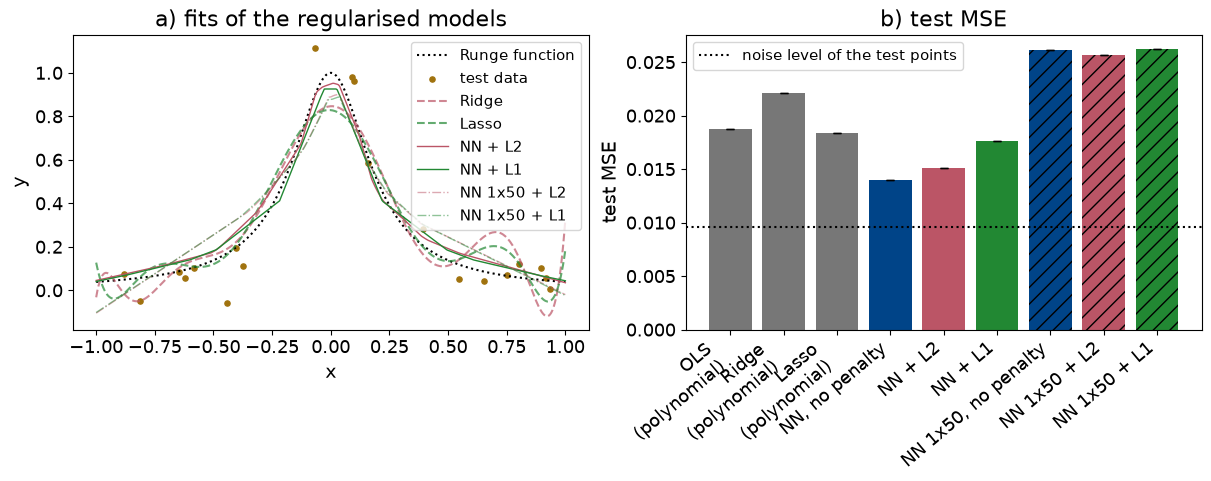

In [ ]:
###################################
# final training, comparison with OLS / Ridge / Lasso
###################################
seeds = [2026]
# seeds = range(10) #for a mean +- spread over several runs (10 times slower)

# 1x50 network chosen with the 1-se rule, without penalty and with L2 / L1 (set your lambdas)
choice["unpenalised_1se"] = ([50], 0.0, "l2", None)
choice["l2_1se"] = ([50], 1e-3, "l2", None)
choice["l1_1se"] = ([50], 1e-3, "l1", None)

x_mean, x_std = x_tr_raw.mean(), x_tr_raw.std() # the same scaling as in prepare_data
xx = np.linspace(-1, 1, 400) # dense grid for plotting the fits
xx_std = ((xx - x_mean) / x_std).reshape(-1, 1)

final = {} # name -> dict with the results
for name, (hid, lam, norm, _) in choice.items():
    tr_err, te_err = [], []
    for seed in seeds:
        layers, act, der = build_net(hid, seed=seed)
        if '1se' in name:
            best_gamma = 0.001
        else:
            best_gamma = 0.005
        layers, hist = train_penalised(layers, x_tr, y_tr, x_te, y_te, "adam", act, der,
                                       best_gamma, 200, lam, norm, seed=seed)
        tr_err.append(hist[-1, 1]) # MSE after the last epoch
        te_err.append(hist[-1, 2])
        if seed == seeds[0]: # keep the fit of the first run for the plot
            curve = feed_forward_batch(xx_std, layers, act)[:, 0]
    final[name] = dict(train=np.mean(tr_err), test=np.mean(te_err), test_std=np.std(te_err), curve=curve)

### Table
print(f"\n{'model':30s} {'settings':34s} {'train MSE':>9s} {'test MSE':>9s}")
rows = []
for kind in ["OLS", "Ridge", "Lasso"]:
    cv_err, d, lam, tr_m, te_m = baseline[kind]
    s = f"degree {d}" + ("" if kind == "OLS" else f", lambda={lam:.0e}")
    rows.append((kind + " (polynomial)", s, tr_m, te_m, 0.0))
for name, label in [("unpenalised", "NN, no penalty"), ("l2", "NN + L2"), ("l1", "NN + L1"),
                    ("unpenalised_1se", "NN 1x50, no penalty"), ("l2_1se", "NN 1x50 + L2"), ("l1_1se", "NN 1x50 + L1")]:
    hid, lam, norm, _ = choice[name]
    s = f"{len(hid)}x{hid[0]}, lambda={lam:g}, gamma={best_gamma}"
    rows.append((label, s, final[name]["train"], final[name]["test"], final[name]["test_std"]))
for r in rows:
    spread = f" +- {r[4]:.4f}" if r[4] > 0 else "" # the spread only exists with several seeds
    print(f"{r[0]:30s} {r[1]:34s} {r[2]:9.4f} {r[3]:9.4f}{spread}")
print(f"{'noise level of test points':30s} {'':34s} {'':9s} {noise_floor:9.4f}")

### Figure: (a) fits of the regularised models, (b) test MSE of all models
fig, ax = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)

ax[0].plot(xx, runge(xx), "k:", label="Runge function")
ax[0].scatter(x_te_raw, y_te_raw, s=14, color="#A0720E", label="test data")
ax[0].plot(xx, baseline_models["Ridge"].predict(xx.reshape(-1, 1)), color=RED, alpha=0.7, ls="--", label="Ridge")
ax[0].plot(xx, baseline_models["Lasso"].predict(xx.reshape(-1, 1)), color=GREEN, alpha=0.7, ls="--", label="Lasso")
ax[0].plot(xx, final["l2"]["curve"], color=RED, ls="-", lw=1, alpha=1, label="NN + L2")
ax[0].plot(xx, final["l1"]["curve"], color=GREEN, ls="-", lw=1, alpha=1, label="NN + L1")
ax[0].plot(xx, final["l2_1se"]["curve"], color=RED, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L2")
ax[0].plot(xx, final["l1_1se"]["curve"], color=GREEN, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L1")
ax[0].set_xlabel("x", fontsize=label_fontsize); ax[0].set_ylabel("y", fontsize=label_fontsize); ax[0].legend(fontsize=legend_fontsize)
ax[0].set_title("a) fits of the regularised models", fontsize=title_fontsize)
ax[0].tick_params(axis="both", which="major", labelsize=tick_fontsize)

labels = [r[0] for r in rows]
bars = ax[1].bar(range(len(rows)), [r[3] for r in rows], yerr=[r[4] for r in rows],
                 color=[GREY, GREY, GREY, BLUE, RED, GREEN, BLUE, RED, GREEN], capsize=3) 
for b in bars[6:]:
    b.set_hatch("//") # hatched = the 1x50 network chosen with the 1-se rule
ax[1].axhline(noise_floor, color="k", ls=":", label="noise level of the test points")
ax[1].set_xticks(range(len(rows)))
ax[1].set_xticklabels([l.replace(" (polynomial)", "\n(polynomial)") for l in labels], rotation=40, ha="right", fontsize=tick_fontsize)
ax[1].set_ylabel("test MSE", fontsize=label_fontsize); ax[1].legend(fontsize=legend_fontsize)
ax[1].set_title("b) test MSE", fontsize=title_fontsize)
ax[1].tick_params(axis="both", which="major", labelsize=tick_fontsize)
# plt.savefig("./figures/partd_comparison.png", dpi=500)
plt.show()